In [58]:
import numpy as np
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings(action='ignore')
import folium
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import time
from googlesearch import search

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
#아래는 한글을 사용할 때 깨지는 문제에 대한 해결
from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname="c:/Windows/Fonts/malgun.ttf").get_name()
rc('font', family=font_name)

#그래프의 축 등에서 음수를 표시할 때 minus sign이 깨지는 것 해결
import matplotlib as mpl
mpl.rcParams['axes.unicode_minus'] = False

In [61]:
#data import
main_df = pd.read_csv('./ai_student_visualization_data_filled.csv', encoding='cp949')
#main data를 미리 볼 수 있음
main_df.head()

,student_id,class_name,course,month,model_type,study_hours,attendance_rate,login_time,error_count,quiz_score,project_score,accuracy,training_time
0,1,빅데이터반,딥러닝,5월,Random Forest,45.0,89.8,9.87,2,91.1,94.2,90.5,7.3
1,2,클라우드반,딥러닝,6월,SVM,48.9,95.5,9.56,2,87.9,90.4,81.3,8.0
2,3,데이터분석반,Python,3월,SVM,63.0,76.7,9.71,2,94.2,100.0,84.9,4.5
3,4,빅데이터반,데이터시각화,5월,Neural Network,55.5,73.9,9.56,2,96.5,100.0,89.4,12.6
4,5,빅데이터반,SQL,3월,Neural Network,42.3,75.8,8.75,4,88.2,96.4,89.4,11.7


In [62]:
main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       500 non-null    int64  
 1   class_name       500 non-null    object 
 2   course           500 non-null    object 
 3   month            500 non-null    object 
 4   model_type       500 non-null    object 
 5   study_hours      500 non-null    float64
 6   attendance_rate  500 non-null    float64
 7   login_time       500 non-null    float64
 8   error_count      500 non-null    int64  
 9   quiz_score       500 non-null    float64
 10  project_score    500 non-null    float64
 11  accuracy         500 non-null    float64
 12  training_time    500 non-null    float64
dtypes: float64(7), int64(2), object(4)
memory usage: 50.9+ KB


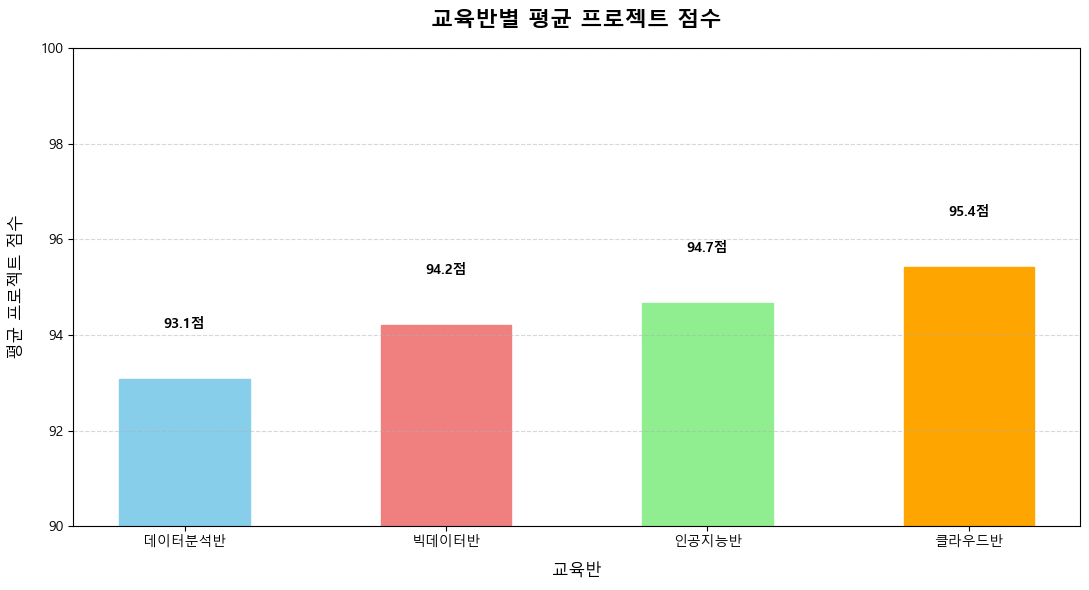

In [63]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일 불러오기
df = pd.read_csv('ai_student_visualization_data_filled.csv', encoding='cp949')


# 2. 교육반별 그룹화 및 프로젝트 점수 평균 계산
df_class = df.groupby('class_name')['project_score'].mean().reset_index()

# 3. 한글 폰트 설정 (깨짐 방지)
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 
plt.rcParams['axes.unicode_minus'] = False     

colors = ['skyblue', 'lightcoral', 'lightgreen', 'orange']
# 4. 그래프 크기 설정 및 막대그래프(bar) 그리기
plt.figure(figsize=(11, 6))
bars = plt.bar(df_class['class_name'], df_class['project_score'],width=0.5)

# 5. 그래프 제목 및 축 레이블 추가
plt.title('교육반별 평균 프로젝트 점수', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('교육반', fontsize=12, labelpad=10)
plt.ylabel('평균 프로젝트 점수', fontsize=12, labelpad=10)

# 6. Y축 그리드(배경 가로 눈금선) 추가
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

# 7. 각 막대 위에 데이터 값(점수) 표시
for i, bar in enumerate(bars):
    # 준비해 둔 colors 리스트에서 i번째 색상을 꺼내 막대에 칠함

    bar.set_color(colors[i % len(colors)])

    height = bar.get_height()
    # 막대의 가장 상단 중앙(ha='center')에 소수점 첫째 자리까지 점수 표시

    plt.text(bar.get_x() + bar.get_width()/2.0, height + 1, f'{height:.1f}점', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# 8. Y축 여백 및 출력 설정
# 점수가 0점부터 시작하면 막대 차이가 잘 안 보일 수 있으므로 최솟값을 조정
plt.ylim(90, 100) 
plt.tight_layout()
plt.show()

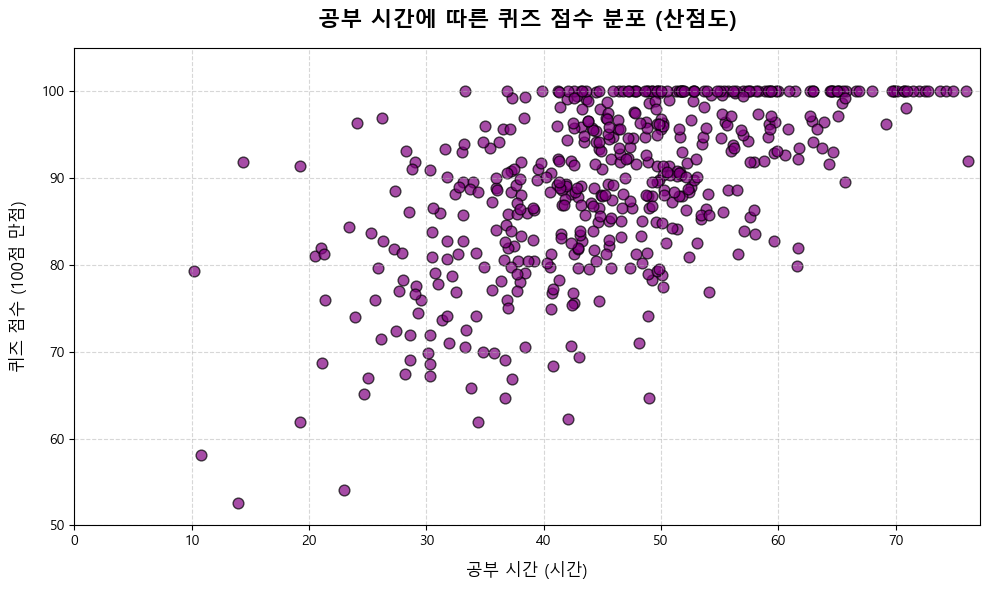

In [64]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일 불러오기
df = pd.read_csv('ai_student_visualization_data_filled.csv', encoding='cp949') 

# 2. 한글 폰트 설정 (깨짐 방지)
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우
plt.rcParams['axes.unicode_minus'] = False     

# 3. 그래프 크기 설정 및 산점도(scatter) 그리기
plt.figure(figsize=(10, 6))

# plt.scatter() 함수를 사용하여 점을 찍습니다.
# s: 점의 크기, c: 점의 색상, alpha: 투명도(0~1, 점이 겹치는 부위를 확인하기 좋음)
plt.scatter(df['study_hours'], df['quiz_score'], s=60, c='purple', alpha=0.7, edgecolors='black')

# 4. 그래프 제목 및 축 레이블 추가
plt.title('공부 시간에 따른 퀴즈 점수 분포 (산점도)', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('공부 시간 (시간)', fontsize=12, labelpad=10)
plt.ylabel('퀴즈 점수 (100점 만점)', fontsize=12, labelpad=10)

# 5. 그리드(배경 격자선) 추가
plt.grid(True, linestyle='--', alpha=0.5)

# 6. 축 범위 설정
plt.xlim(0, max(df['study_hours']) + 1)
plt.ylim(50, 105)

# 7. 그래프 출력
plt.tight_layout()
plt.show()

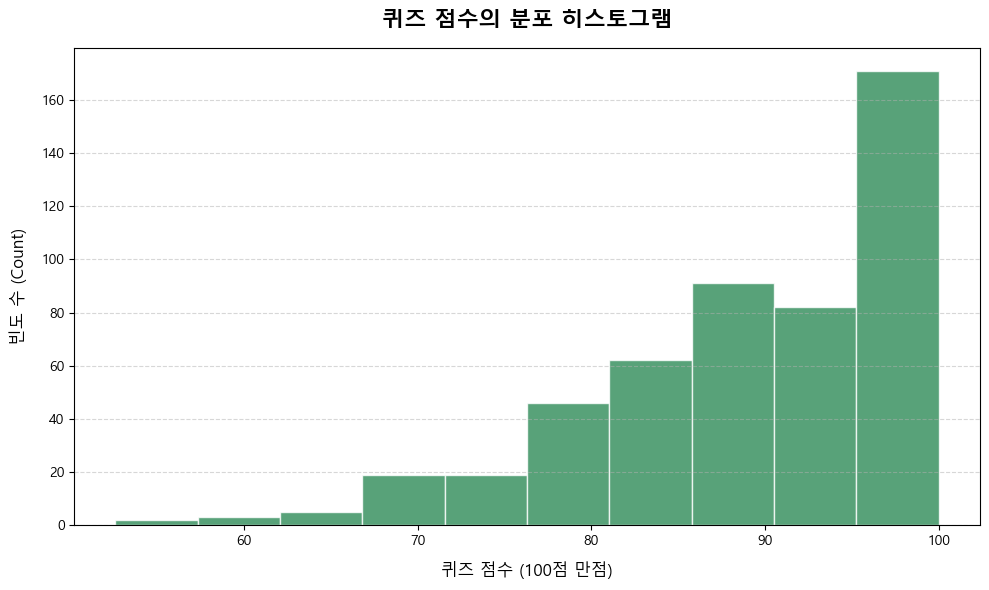

In [65]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일 불러오기
df = pd.read_csv('ai_student_visualization_data_filled.csv', encoding='cp949') 

# 2. 한글 폰트 설정 (깨짐 방지)
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우
plt.rcParams['axes.unicode_minus'] = False     

# 3. 그래프 크기 설정 및 히스토그램(hist) 그리기
plt.figure(figsize=(10, 6))

# bins: 구간을 몇 개로 쪼갤지 설정 (예: 10개 구간)
# edgecolor: 막대 사이의 경계선 색상
plt.hist(df['quiz_score'], bins=10, color='seagreen', edgecolor='white', alpha=0.8)

# 4. 그래프 제목 및 축 레이블 추가
plt.title('퀴즈 점수의 분포 히스토그램', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('퀴즈 점수 (100점 만점)', fontsize=12, labelpad=10)
plt.ylabel('빈도 수 (Count)', fontsize=12, labelpad=10)

# 5. Y축 그리드(배경 가로 눈금선) 추가
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

# 6. 그래프 출력
plt.tight_layout()
plt.show()

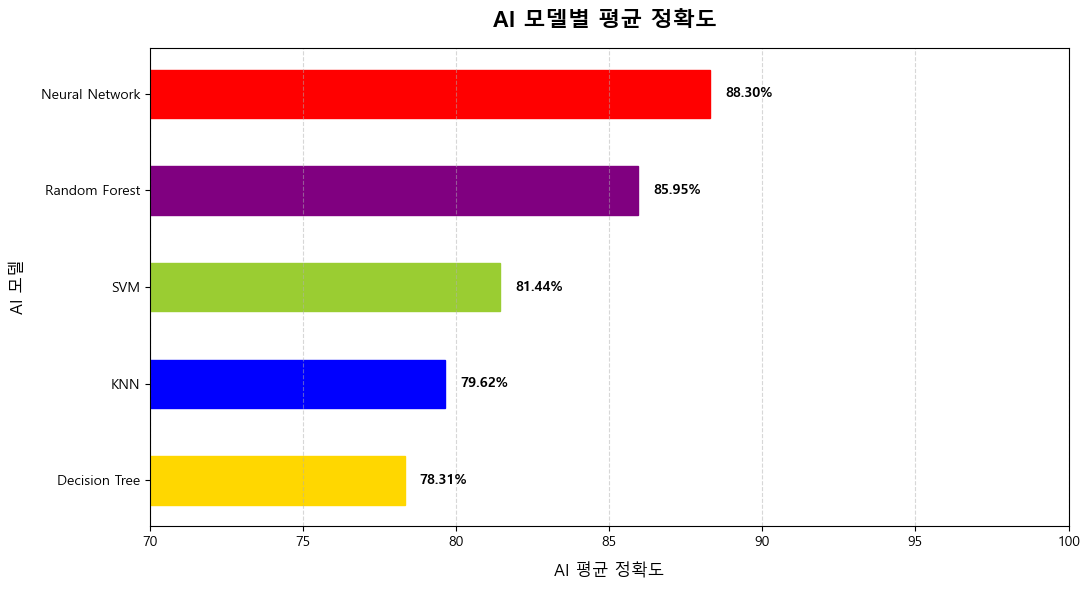

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일 불러오기
df = pd.read_csv('ai_student_visualization_data_filled.csv', encoding='cp949')


# 2. AI모델별 그룹화 및 모델의 정확도 평균 계산
df_model = df.groupby('model_type')['accuracy'].mean().reset_index()

# 2.1 평균 정확도가 높은 모델이 위로 오도록 정렬
df_model = df_model.sort_values(by='accuracy', ascending=True)

# 3. 한글 폰트 설정 (깨짐 방지)
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 
plt.rcParams['axes.unicode_minus'] = False     

colors = ['gold', 'blue', 'yellowgreen', 'purple', 'red']
# 4. 그래프 크기 설정 및 막대그래프(bar) 그리기
plt.figure(figsize=(11, 6))
bars = plt.barh(df_model['model_type'], df_model['accuracy'],height=0.5)  #막대그래프 두께 조절 가로이므로, height

# 5. 그래프 제목 및 축 레이블 추가
plt.title('AI 모델별 평균 정확도 ', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('AI 평균 정확도', fontsize=12, labelpad=10)
plt.ylabel('AI 모델', fontsize=12, labelpad=10)

# 6. x축 그리드(배경 가로 눈금선) 추가
plt.grid(True, axis='x', linestyle='--', alpha=0.5)

# 7. 각 막대 위에 데이터 값(점수) 표시
for i, bar in enumerate(bars):
    # 준비해 둔 colors 리스트에서 i번째 색상을 꺼내 막대에 입힙니다.

    bar.set_color(colors[i % len(colors)])

    width = bar.get_width()
   # 가로 막대이므로 텍스트를 막대의 오른쪽 끝(width + 알파, y축 중앙)에 표시
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2.0, f'{width:.2f}%', 
             va='center', ha='left', fontsize=10, fontweight='bold')

# 8. Y축 여백 및 출력 설정
# 점수가 0점부터 시작하면 막대 차이가 잘 안 보일 수 있으므로 최솟값을 조정
plt.xlim(70, 100) 
plt.tight_layout()
plt.show()

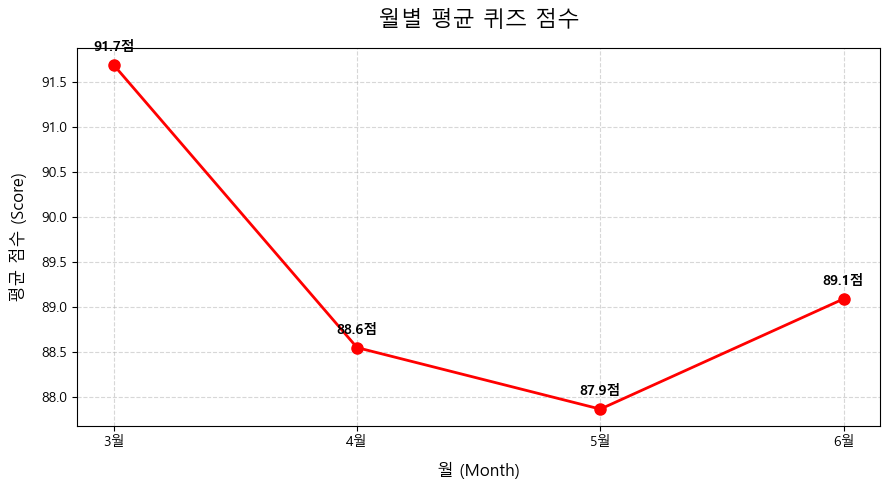

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일 불러올 때
df = pd.read_csv('ai_student_visualization_data_filled.csv', encoding='cp949')

# 2. 월별 그룹화 및 퀴즈 점수 평균 계산
df_monthly = df.groupby('month')['quiz_score'].mean().reset_index()

# 3. 한글 폰트 설정 (깨짐 방지)
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 
plt.rcParams['axes.unicode_minus'] = False     # 마이너스 부호 깨짐 방지

# 4. 데이터프레임 기반으로 그래프 크기 설정 및 그리기
plt.figure(figsize=(9, 5))
plt.plot(df_monthly['month'], df_monthly['quiz_score'], marker='o', color='r', linestyle='-', linewidth=2, markersize=8)

# 5. 그래프 제목 및 축 레이블 추가
plt.title('월별 평균 퀴즈 점수', fontsize=16, pad=15)
plt.xlabel('월 (Month)', fontsize=12, labelpad=10)
plt.ylabel('평균 점수 (Score)', fontsize=12, labelpad=10)

# 6. 그리드(배경 눈금선) 추가
plt.grid(True, linestyle='--', alpha=0.5)

# 7. 각 점 위에 데이터 값 표시
for i, txt in enumerate(df_monthly['quiz_score']):
    plt.annotate(f'{txt:.1f}점', 
                 (df_monthly['month'].iloc[i], df_monthly['quiz_score'].iloc[i]), 
                 textcoords="offset points", 
                 xytext=(0, 10), 
                 ha='center', 
                 fontsize=10, 
                 fontweight='bold')

# 7. 그래프 출력
plt.tight_layout()
plt.show()

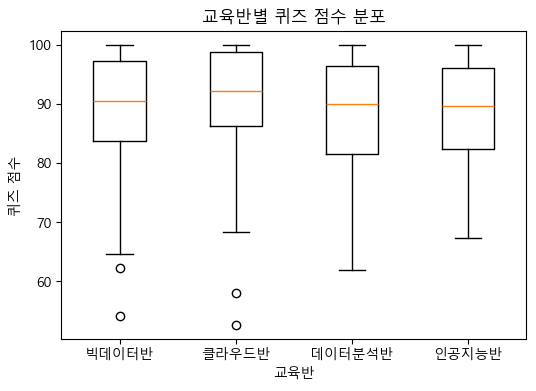

In [68]:
df = main_df
plt.figure(figsize=(6, 4))
classes = df['class_name'].unique()
data_box = [df[df['class_name'] == c]['quiz_score'].dropna() for c in classes]

# 수정된 부분: boxplot 내부의 labels=classes를 지우고 plt.xticks() 사용
plt.boxplot(data_box)
plt.xticks(range(1, len(classes) + 1), classes)

plt.title('교육반별 퀴즈 점수 분포')
plt.xlabel('교육반')
plt.ylabel('퀴즈 점수')
plt.show()

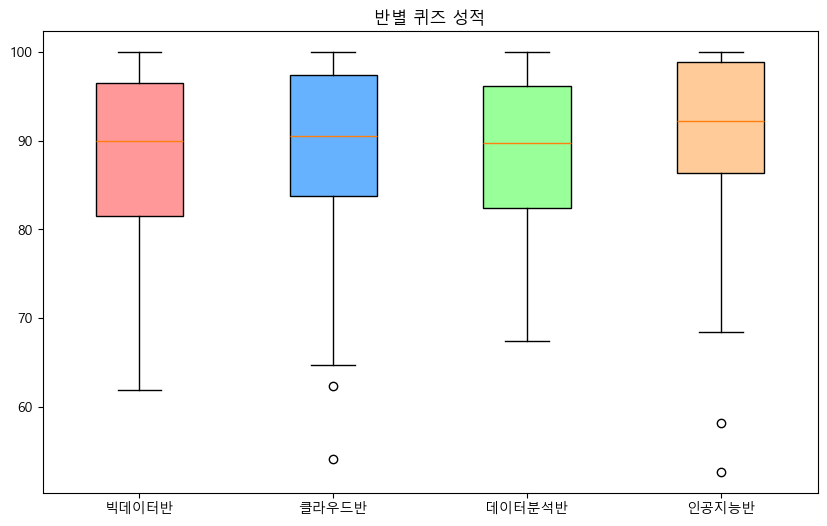

In [69]:
#6번
group_df = main_df.groupby('class_name')['quiz_score']
dt = [group.values for name, group in group_df]
fig, ax = plt.subplots(figsize=(10, 6))
bplot = ax.boxplot(dt,patch_artist=True, labels=main_df['class_name'].unique())
colors = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99']
for i, patch in enumerate(bplot['boxes']):
    patch.set_facecolor(colors[i % len(colors)])

plt.title('반별 퀴즈 성적')
plt.suptitle('')
plt.show()

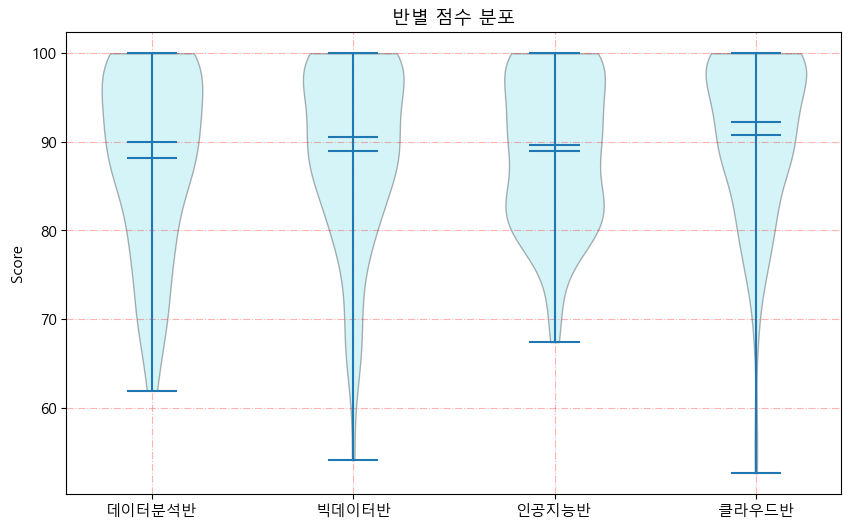

In [70]:
#7번
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

fig, ax = plt.subplots()
plt.grid(True, color='red', alpha=0.3, linestyle='-.')
course_names = sorted(main_df['class_name'].unique())
dt = [main_df[main_df['class_name'] == name]['quiz_score'].dropna() 
                for name in course_names]

vplot = ax.violinplot(dt, showmeans=True, showmedians=True)

ax.set_xticks(range(1, len(course_names) + 1))
ax.set_xticklabels(course_names)
ax.set_ylabel('Score')

for pc in vplot['bodies']:
    pc.set_facecolor("#76DBE6")
    pc.set_edgecolor('black')
plt.title('반별 점수 분포')
plt.show()

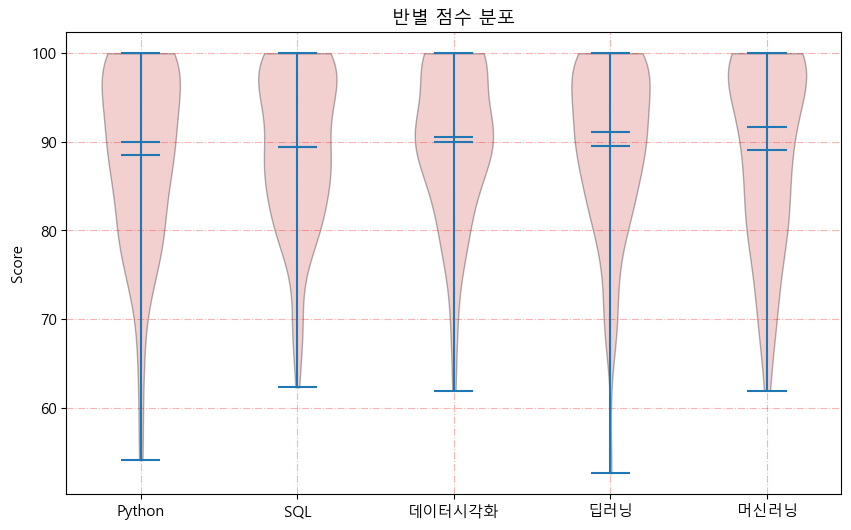

       quiz_score
count    5.000000
mean    89.302893
std      0.521889
min     88.566162
25%     89.052747
50%     89.410909
75%     89.534649
max     89.950000


In [71]:
#7번
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

fig, ax = plt.subplots()
plt.grid(True, color='red', alpha=0.3, linestyle='-.')
course_names = sorted(main_df['course'].unique())
dt = [main_df[main_df['course'] == name]['quiz_score'].dropna() 
                for name in course_names]

vplot = ax.violinplot(dt, showmeans=True, showmedians=True)

ax.set_xticks(range(1, len(course_names) + 1))
ax.set_xticklabels(course_names)
ax.set_ylabel('Score')

for pc in vplot['bodies']:
    pc.set_facecolor("#D86565")
    pc.set_edgecolor('black')
plt.title('반별 점수 분포')
plt.show()
group_df = main_df.groupby('course')['quiz_score'].mean().reset_index()
print(group_df.describe())

In [72]:
main_df.groupby('course').describe()

student_id                                                              \
            count        mean         std   min     25%    50%     75%    max   
course                                                                          
Python       99.0  253.676768  140.724715   3.0  140.50  254.0  365.50  482.0   
SQL         110.0  239.200000  157.995517   5.0  103.25  234.5  390.75  498.0   
데이터시각화       86.0  277.941860  148.847680   4.0  154.00  285.0  411.50  500.0   
딥러닝         114.0  250.631579  136.772808   1.0  134.75  249.0  367.25  496.0   
머신러닝         91.0  234.604396  135.608331  27.0  118.00  232.0  321.50  495.0   

       study_hours             ... accuracy       training_time            \
             count       mean  ...      75%   max         count      mean   
course                         ...                                          
Python        99.0  45.990404  ...   85.350  96.3          99.0  6.037374   
SQL          110.0  45.562727  ...   88.400  98.0         110.0  7.293636   
데이터시각화        86.0  45.720930  ...   86.650  94.3          86.0  6.356977   
딥러닝          114.0  46.844737  ...   85.375  91.0         114.0  6.393860   
머신러닝          91.0  46.112088  ...   86.700  92.7          91.0  6.742857   

                                                 
             std  min    25%   50%    75%   max  
course                                           
Python  3.132828  1.0  3.900  5.40  7.600  14.5  
SQL     3.549448  1.0  4.525  6.15  9.800  15.3  
데이터시각화  3.312278  1.0  3.725  6.30  8.575  13.9  
딥러닝     3.244281  1.0  4.225  5.80  8.175  14.1  
머신러닝    3.186923  1.0  4.750  6.20  8.500  14.8  

[5 rows x 72 columns]

In [73]:
main_df.head(1)

,student_id,class_name,course,month,model_type,study_hours,attendance_rate,login_time,error_count,quiz_score,project_score,accuracy,training_time
0,1,빅데이터반,딥러닝,5월,Random Forest,45.0,89.8,9.87,2,91.1,94.2,90.5,7.3


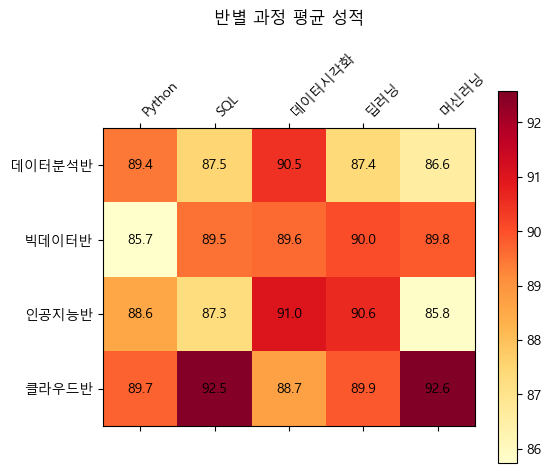

class_name        클라우드반
course             머신러닝
quiz_score    92.576667
dtype: object

In [74]:
#8번
plt.rcdefaults()
plt.rcParams['font.family'] ='Malgun Gothic'
group_df = main_df.groupby(['class_name','course'])['quiz_score'].mean().reset_index()
df = group_df.pivot(index='class_name', columns='course', values='quiz_score')
plt.matshow(df, cmap='YlOrRd')
plt.xticks(range(len(df.columns)), df.columns, rotation=45, ha='left')
plt.yticks(range(len(df.index)), df.index)
# plt.clim(60, 100)
plt.colorbar()
plt.title('반별 과정 평균 성적', pad=20)
for i in range(len(df.index)):
    for j in range(len(df.columns)):
        text = plt.text(j, i, f'{df.iloc[i, j]:.1f}', 
                        ha='center', va='center', color='black')
plt.show()
group_df.max()

In [75]:
main_df.head()

,student_id,class_name,course,month,model_type,study_hours,attendance_rate,login_time,error_count,quiz_score,project_score,accuracy,training_time
0,1,빅데이터반,딥러닝,5월,Random Forest,45.0,89.8,9.87,2,91.1,94.2,90.5,7.3
1,2,클라우드반,딥러닝,6월,SVM,48.9,95.5,9.56,2,87.9,90.4,81.3,8.0
2,3,데이터분석반,Python,3월,SVM,63.0,76.7,9.71,2,94.2,100.0,84.9,4.5
3,4,빅데이터반,데이터시각화,5월,Neural Network,55.5,73.9,9.56,2,96.5,100.0,89.4,12.6
4,5,빅데이터반,SQL,3월,Neural Network,42.3,75.8,8.75,4,88.2,96.4,89.4,11.7


In [76]:
print(matplotlib.get_cachedir())

C:\Users\smart\.matplotlib


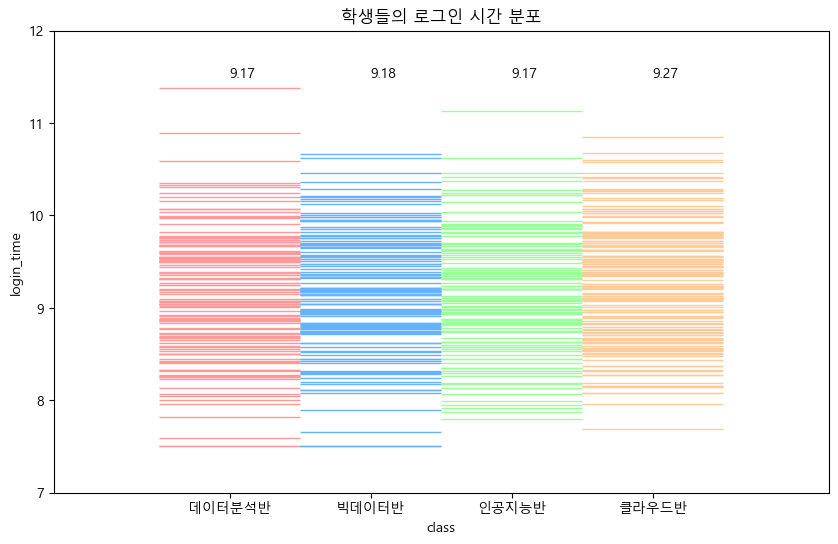

In [77]:
#9번
plt.rcParams['font.family'] ='Malgun Gothic'

colors = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99']
class_names = sorted(main_df['class_name'].unique())
x_positions = np.arange(len(class_names))
fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(class_names):
    data = main_df[main_df['class_name'] == name]['login_time']
    ax.eventplot(data, orientation="vertical", lineoffsets=i,colors=colors[i % len(colors)] ,linewidth=1, label=name)
    ax.text(i, 11.5,round(data.mean(),2))
ax.set(
    ylabel='login_time',
    xlabel='class',
    xticks=x_positions,
    xticklabels=class_names,
    ylim=(7, 12)
)
plt.title('학생들의 로그인 시간 분포')
plt.show()

In [78]:
main_df['logintime'] = main_df['login_time'].astype(int)
main_df.groupby('class_name')['logintime'].value_counts()

class_name  logintime
데이터분석반      9            63
            8            42
            10           11
            7             5
            11            1
빅데이터반       9            60
            8            46
            10           12
            7             4
인공지능반       9            52
            8            40
            10           10
            7             5
            11            1
클라우드반       9            78
            8            48
            10           20
            7             2
Name: count, dtype: int64

In [79]:
def graph4():    
    scatter_data = main_df.copy()

    # 사용할 컬럼
    columns = ['study_hours', 'attendance_rate', 'quiz_score']

    # 숫자형으로 변환
    for column in columns:
        scatter_data[column] = pd.to_numeric(
            scatter_data[column]
            .astype('string')
            .str.replace('%', '', regex=False)
            .str.strip(),
            errors='coerce'
        )

    # 3D 그래프 영역 생성
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # 3D 산점도 그리기
    scatter = ax.scatter(
        scatter_data['study_hours'],
        scatter_data['attendance_rate'],
        scatter_data['quiz_score'],
        c=scatter_data['quiz_score'],
        cmap='viridis',
        s=45,
        alpha=0.7,
        edgecolor='white',
        linewidth=0.4
    )

    # 축 범위 조정
    ax.set_xlim(10, 75)    # 공부시간
    ax.set_ylim(65, 100)   # 출석률
    ax.set_zlim(50, 100)   # 퀴즈 점수

    # 축 이름
    ax.set_xlabel('공부시간', labelpad=10)
    ax.set_ylabel('출석률 (%)', labelpad=10)
    ax.set_zlabel('퀴즈 점수', labelpad=10)

    # 그래프 제목
    ax.set_title(
        '공부시간·출석률·퀴즈 점수의 3D 산점도',
        fontsize=15,
        fontweight='bold',
        pad=10
    )

    # 보는 각도 설정
    ax.view_init(elev=25, azim=45)

    # 색상 막대
    colorbar = fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.7,
        pad=0.1
    )

    colorbar.set_label('퀴즈 점수')
    colorbar.outline.set_visible(False)

    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


In [80]:
def graph3():    
    donut_data = main_df.copy()

    #  AI 모델을 3개 계열로 묶기
    model_group_map = {
        'decision tree': '트리계열',
        'random forest': '트리계열',
        'knn': '전통ML',
        'svm': '전통ML',
        'neural network': '신경망'
    }

    # 대소문자를 통일한 뒤 모델계열로 변환
    donut_data['model_group'] = (
        donut_data['model_type']
        .str.casefold()
        .map(model_group_map)
    )


    # 종합 점수 계산
    score_columns = ['quiz_score', 'project_score', 'accuracy']

    # 점수 컬럼 숫자형 변환
    for column in score_columns:
        donut_data[column] = pd.to_numeric(
            donut_data[column],
            errors='coerce'
        )

    # 퀴즈 점수, 프로젝트 점수, 정확도의 평균
    donut_data['avg_score'] = (donut_data[score_columns].mean(axis=1))

    # 실제 점수 기준으로 성과등급 생성
    # 하: 85점 미만
    # 중: 85점 이상 90점 미만
    # 상: 90점 이상
    donut_data['score_grade'] = pd.cut(
        donut_data['avg_score'],
        bins=[-np.inf, 85, 90, np.inf],
        labels=['하', '중', '상'],
        right=False
    )

    # 계층 라벨 설정 / 바깥: 교육반 → 가운데: 모델계열 → 안쪽: 성과등급
    outer_labels = (donut_data['class_name'].unique().tolist())
    model_group_labels = ['트리계열', '전통ML', '신경망']
    score_grade_labels = ['하', '중', '상']

    # 학생 수 집계
    group_counts = (donut_data.groupby(
            ['class_name', 'model_group', 'score_grade'],
            observed=True
        ).size()
    )

    # 가능한 모든 조합 생성
    full_index = pd.MultiIndex.from_product(
        [
            outer_labels,
            model_group_labels,
            score_grade_labels
        ],
        names=[
            'class_name',
            'model_group',
            'score_grade'
        ]
    )

    # 존재하지 않는 조합은 0으로 채우기
    group_counts = group_counts.reindex(full_index, fill_value=0)

    vals = group_counts.to_numpy().reshape(
        len(outer_labels),
        len(model_group_labels),
        len(score_grade_labels)
    ).astype(float)

    # 고리 라벨
    middle_labels = [model_group_labels.copy() for _ in outer_labels]
    inner_labels = [[score_grade_labels.copy() for _ in model_group_labels] for _ in outer_labels]

    total = vals.sum()
    valsnorm = vals / total * 2 * np.pi

    flat = valsnorm.flatten()
    starts_flat = np.concatenate([[0], np.cumsum(flat[:-1])])
    starts = starts_flat.reshape(vals.shape)

    # 그래프 그리자
    fig, ax = plt.subplots(figsize=(16, 12), subplot_kw=dict(projection='polar'))

    ax.set_title(
        '교육반별 AI 모델계열 및 성과등급\n3단계 계층형 도넛 차트',
        fontsize=17,
        fontweight='bold',
        pad=20
    )
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ring = 0.2

    # 바깥 고리: 교육반
    outer_palette = [
        '#B8DDD3',  # 파스텔 민트
        '#BFCDE5',  # 파스텔 블루
        '#F6DDA4',  # 파스텔 옐로
        '#D9C2E9',  # 파스텔 퍼플
        '#F4C5C0',  # 파스텔 핑크
        '#C3E0E5'   # 파스텔 스카이
    ]

    outer_colors = [outer_palette[i % len(outer_palette)] for i in range(len(outer_labels))]

    # 가운데 고리: 모델계열
    model_group_colors = [
        '#A9CBE8',  # 트리계열: 파스텔 블루
        '#B7DEBE',  # 전통ML: 파스텔 그린
        '#D6BFE5'   # 신경망: 파스텔 퍼플
    ]

    # 교육반마다 세 가지 색상 반복
    middle_colors = (model_group_colors * len(outer_labels))


    # 안쪽 고리: 성과등급
    grade_colors = [
        '#F4BFC1',  # 하: 파스텔 핑크
        '#F7DEA0',  # 중: 파스텔 옐로
        '#B8DFC4'   # 상: 파스텔 그린
    ]

    # 교육반 수 × 모델계열 수만큼 반복
    inner_colors = (
        grade_colors
        * (
            len(outer_labels)
            * len(model_group_labels)
        )
    )


    # =========================================================
    # 바깥 고리: 교육반
    # =========================================================

    outer_widths = valsnorm.sum(axis=(1, 2))
    outer_starts = starts[:, 0, 0]

    ax.bar(
        x=outer_starts,
        width=outer_widths,
        bottom=1 - ring,
        height=ring,
        color=outer_colors,
        edgecolor='white',
        linewidth=2,
        align='edge'
    )

    # 교육반 이름과 학생 수 표시
    for i in range(len(outer_labels)):

        group_sum = int(vals[i].sum())

        if group_sum == 0:
            continue

        theta_center = (outer_starts[i] + outer_widths[i] / 2)
        r_center = 1 - ring / 2

        ax.text(
            theta_center,
            r_center,
            f'{outer_labels[i]}\n{group_sum}',
            ha='center',
            va='center',
            fontsize=10,
            fontweight='bold'
        )


    # =========================================================
    # 가운데 고리: 모델계열
    # =========================================================

    # 성과등급 축을 합산
    middle_widths = valsnorm.sum(axis=2)

    # 각 모델계열의 첫 성과등급 시작 위치
    middle_starts = starts[:, :, 0]

    ax.bar(
        x=middle_starts.flatten(),
        width=middle_widths.flatten(),
        bottom=1 - 2 * ring,
        height=ring,
        color=middle_colors,
        edgecolor='white',
        linewidth=1.5,
        align='edge'
    )

    # 모델계열 이름과 학생 수 표시
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            middle_sum = int(vals[i, j].sum())

            if middle_sum == 0:
                continue

            theta_center = (middle_starts[i, j] + middle_widths[i, j] / 2)
            r_center = 1 - 1.5 * ring

            ax.text(
                theta_center,
                r_center,
                f'{middle_labels[i][j]}\n{middle_sum}',
                ha='center',
                va='center',
                fontsize=8
            )


    # =========================================================
    # 14. 안쪽 고리: 성과등급
    # =========================================================

    ax.bar(
        x=starts.flatten(),
        width=valsnorm.flatten(),
        bottom=1 - 3 * ring,
        height=ring,
        color=inner_colors,
        edgecolor='white',
        linewidth=1.2,
        align='edge'
    )

    # 상·중·하와 학생 수 표시
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            for k in range(vals.shape[2]):
                grade_count = int(vals[i, j, k])

                if grade_count == 0:
                    continue

                theta_center = (starts[i, j, k] + valsnorm[i, j, k] / 2)
                r_center = 1 - 2.5 * ring

                ax.text(
                    theta_center,
                    r_center,
                    f'{inner_labels[i][j][k]}\n{grade_count}',
                    ha='center',
                    va='center',
                    fontsize=7
                )


    # =========================================================
    # 15. 그래프 마무리
    # =========================================================

    # 중앙에는 아무 글자도 표시하지 않음
    ax.set_axis_off()
    ax.set_ylim(0, 1.03)

    plt.tight_layout()
    plt.show()


    # =========================================================
    # 16. 결과 확인
    # =========================================================

    print('계층 구조: 교육반 → 모델계열 → 성과등급')
    print('vals 크기:', vals.shape)
    print('전체 인원:', int(vals.sum()))

    print('\n성과등급별 인원')
    print(
        donut_data['score_grade']
        .value_counts()
        .sort_index()
    )

    print('\n성과등급별 종합점수 요약')
    display(
        donut_data
        .groupby('score_grade', observed=True)['avg_score']
        .agg(['count', 'min', 'mean', 'max'])
        .round(1)
    )

In [81]:
def graph2():
    df_model = main_df.groupby('model_type')['accuracy'].mean().reset_index()

    # 2.1 평균 정확도가 높은 모델이 위로 오도록 정렬
    df_model = df_model.sort_values(by='accuracy', ascending=True)

    # 3. 한글 폰트 설정 (깨짐 방지)
    plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 
    plt.rcParams['axes.unicode_minus'] = False     

    colors = ['gold', 'blue', 'yellowgreen', 'purple', 'red']
    # 4. 그래프 크기 설정 및 막대그래프(bar) 그리기
    plt.figure(figsize=(11, 6))
    bars = plt.barh(df_model['model_type'], df_model['accuracy'],height=0.5)  #막대그래프 두께 조절 가로이므로, height

    # 5. 그래프 제목 및 축 레이블 추가
    plt.title('AI 모델별 평균 정확도 ', fontsize=16, pad=15, fontweight='bold')
    plt.xlabel('AI 평균 정확도', fontsize=12, labelpad=10)
    plt.ylabel('AI 모델', fontsize=12, labelpad=10)

    # 6. x축 그리드(배경 가로 눈금선) 추가
    plt.grid(True, axis='x', linestyle='--', alpha=0.5)

    # 7. 각 막대 위에 데이터 값(점수) 표시
    for i, bar in enumerate(bars):
        # 준비해 둔 colors 리스트에서 i번째 색상을 꺼내 막대에 입힙니다.

        bar.set_color(colors[i % len(colors)])

        width = bar.get_width()
    # 가로 막대이므로 텍스트를 막대의 오른쪽 끝(width + 알파, y축 중앙)에 표시
        plt.text(width + 0.5, bar.get_y() + bar.get_height()/2.0, f'{width:.2f}%', 
                va='center', ha='left', fontsize=10, fontweight='bold')

    # 8. Y축 여백 및 출력 설정
    # 점수가 0점부터 시작하면 막대 차이가 잘 안 보일 수 있으므로 최솟값을 조정
    plt.xlim(70, 100) 
    plt.tight_layout()
    plt.show()

In [82]:
def graph1():    
    plt.figure(figsize=(10, 6))
    df = main_df

    # plt.scatter() 함수를 사용하여 점을 찍습니다.
    # s: 점의 크기, c: 점의 색상, alpha: 투명도(0~1, 점이 겹치는 부위를 확인하기 좋음)
    plt.scatter(df['study_hours'], df['quiz_score'], s=60, c='purple', alpha=0.7, edgecolors='black')

    # 4. 그래프 제목 및 축 레이블 추가
    plt.title('공부 시간에 따른 퀴즈 점수 분포 (산점도)', fontsize=16, pad=15, fontweight='bold')
    plt.xlabel('공부 시간 (시간)', fontsize=12, labelpad=10)
    plt.ylabel('퀴즈 점수 (100점 만점)', fontsize=12, labelpad=10)

    # 5. 그리드(배경 격자선) 추가
    plt.grid(True, linestyle='--', alpha=0.5)

    # 6. 축 범위 설정
    plt.xlim(0, max(df['study_hours']) + 1)
    plt.ylim(50, 105)

    # 7. 그래프 출력
    plt.tight_layout()
    plt.show()

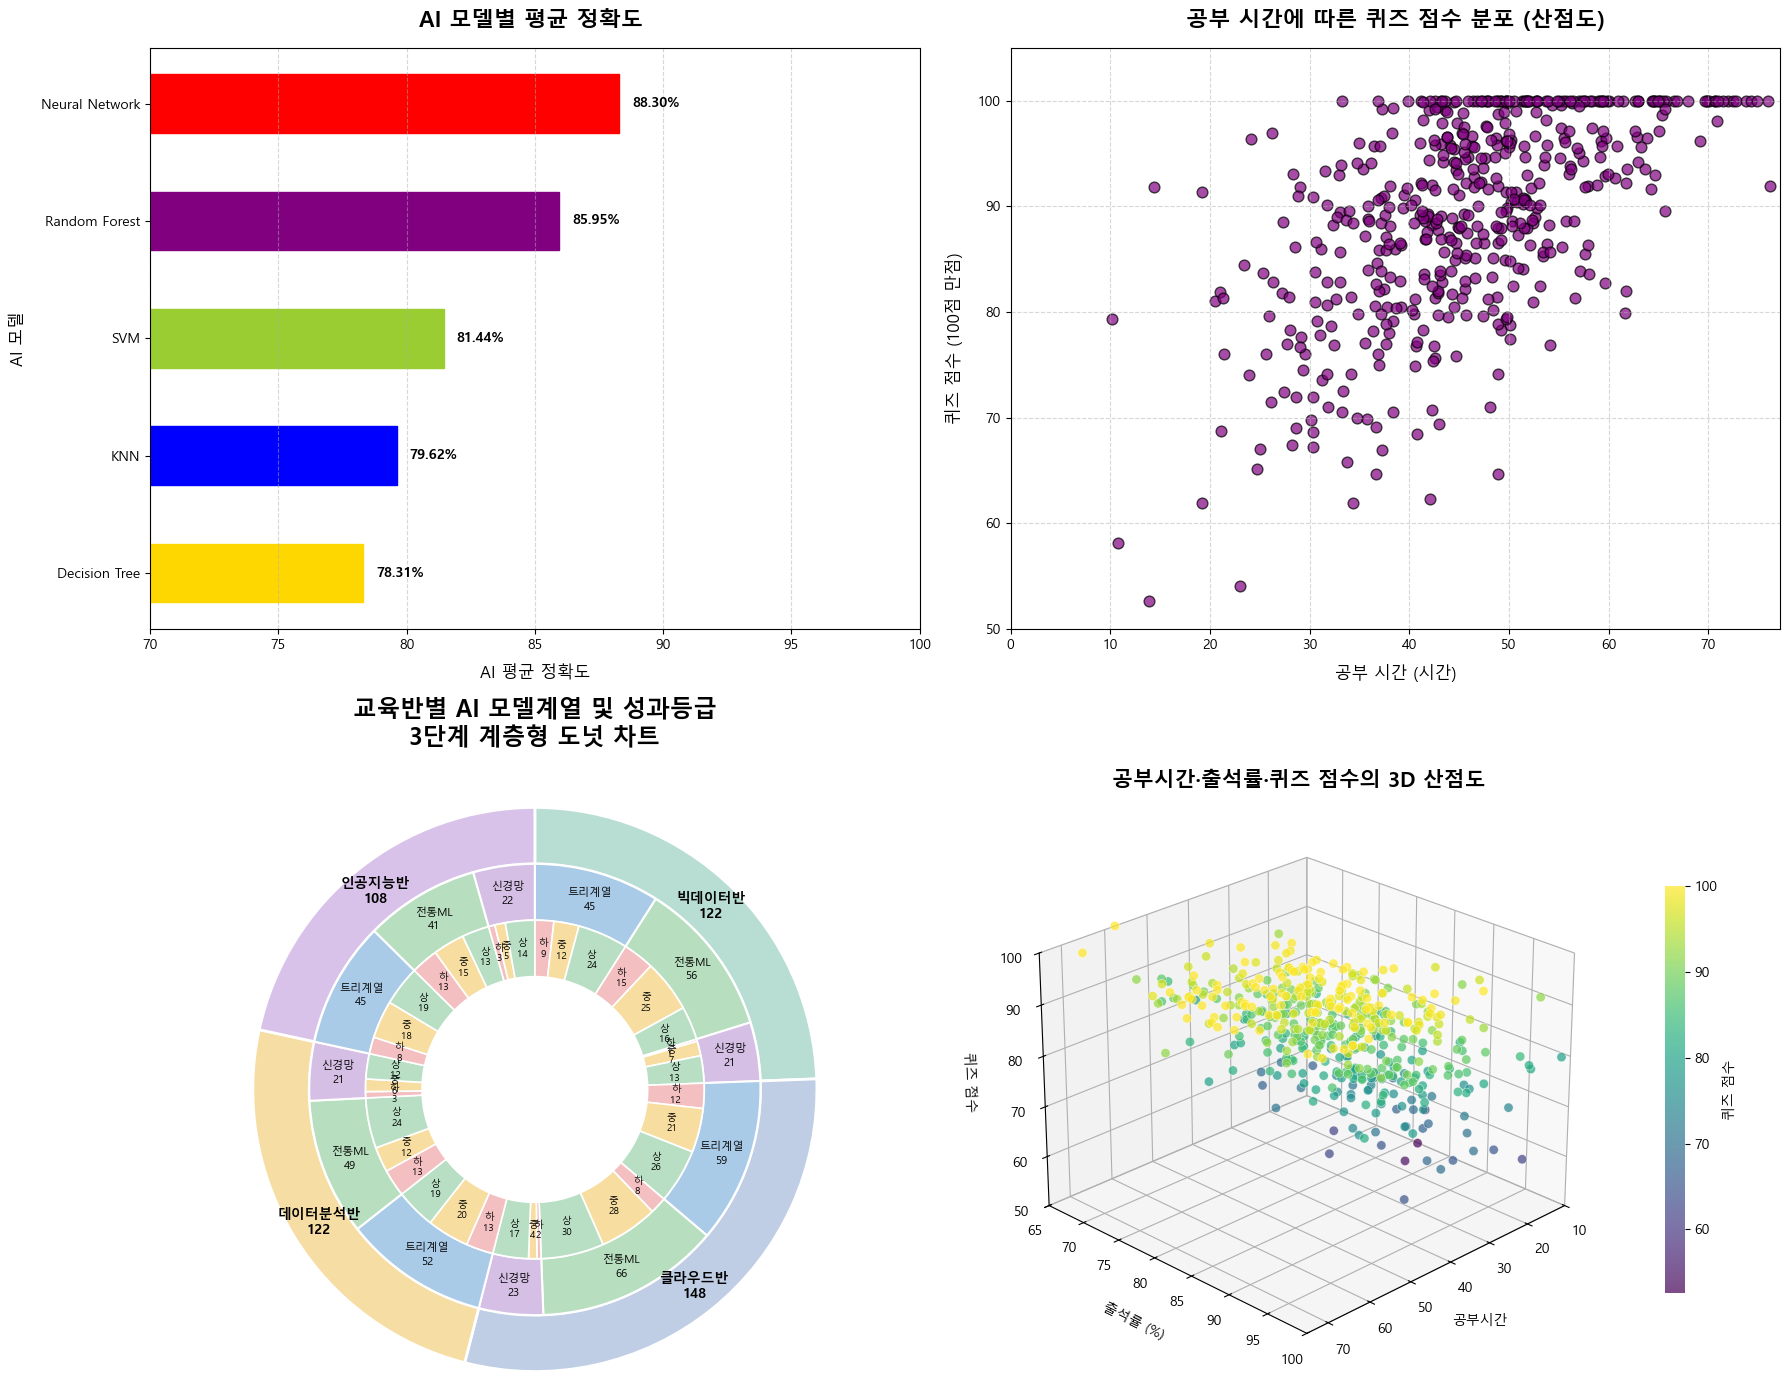

In [83]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ==========================================
# 1. graph4 (3D 산점도)
# ==========================================
def graph4(ax=None):
    if ax is None:
        ax = plt.gca(projection='3d')
        
    scatter_data = main_df.copy()
    columns = ['study_hours', 'attendance_rate', 'quiz_score']
    
    for column in columns:
        scatter_data[column] = pd.to_numeric(
            scatter_data[column].astype('string').str.replace('%', '', regex=False).str.strip(),
            errors='coerce'
        )

    scatter = ax.scatter(
        scatter_data['study_hours'], scatter_data['attendance_rate'], scatter_data['quiz_score'],
        c=scatter_data['quiz_score'], cmap='viridis', s=45, alpha=0.7, edgecolor='white', linewidth=0.4
    )

    ax.set_xlim(10, 75)
    ax.set_ylim(65, 100)
    ax.set_zlim(50, 100)

    ax.set_xlabel('공부시간', labelpad=10)
    ax.set_ylabel('출석률 (%)', labelpad=10)
    ax.set_zlabel('퀴즈 점수', labelpad=10)
    ax.set_title('공부시간·출석률·퀴즈 점수의 3D 산점도', fontsize=15, fontweight='bold', pad=10)
    ax.view_init(elev=25, azim=45)

    # ax가 속한 figure를 찾아서 컬러바 추가
    fig = ax.figure
    colorbar = fig.colorbar(scatter, ax=ax, shrink=0.7, pad=0.1)
    colorbar.set_label('퀴즈 점수')
    colorbar.outline.set_visible(False)
    ax.grid(True, alpha=0.3)


# ==========================================
# 2. graph3 (도넛 차트 - Polar)
# ==========================================
def graph3(ax=None):
    if ax is None:
        ax = plt.gca(projection='polar')
        
    donut_data = main_df.copy()
    model_group_map = {
        'decision tree': '트리계열', 'random forest': '트리계열',
        'knn': '전통ML', 'svm': '전통ML', 'neural network': '신경망'
    }
    donut_data['model_group'] = donut_data['model_type'].str.casefold().map(model_group_map)
    score_columns = ['quiz_score', 'project_score', 'accuracy']
    
    for column in score_columns:
        donut_data[column] = pd.to_numeric(donut_data[column], errors='coerce')
        
    donut_data['avg_score'] = donut_data[score_columns].mean(axis=1)
    donut_data['score_grade'] = pd.cut(
        donut_data['avg_score'], bins=[-np.inf, 85, 90, np.inf], labels=['하', '중', '상'], right=False
    )

    outer_labels = donut_data['class_name'].unique().tolist()
    model_group_labels = ['트리계열', '전통ML', '신경망']
    score_grade_labels = ['하', '중', '상']

    group_counts = donut_data.groupby(['class_name', 'model_group', 'score_grade'], observed=True).size()
    full_index = pd.MultiIndex.from_product(
        [outer_labels, model_group_labels, score_grade_labels],
        names=['class_name', 'model_group', 'score_grade']
    )
    group_counts = group_counts.reindex(full_index, fill_value=0)
    vals = group_counts.to_numpy().reshape(len(outer_labels), len(model_group_labels), len(score_grade_labels)).astype(float)

    middle_labels = [model_group_labels.copy() for _ in outer_labels]
    inner_labels = [[score_grade_labels.copy() for _ in model_group_labels] for _ in outer_labels]

    total = vals.sum()
    valsnorm = vals / total * 2 * np.pi
    flat = valsnorm.flatten()
    starts_flat = np.concatenate([[0], np.cumsum(flat[:-1])])
    starts = starts_flat.reshape(vals.shape)

    ax.set_title('교육반별 AI 모델계열 및 성과등급\n3단계 계층형 도넛 차트', fontsize=17, fontweight='bold', pad=20)
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ring = 0.2

    outer_palette = ['#B8DDD3', '#BFCDE5', '#F6DDA4', '#D9C2E9', '#F4C5C0', '#C3E0E5']
    outer_colors = [outer_palette[i % len(outer_palette)] for i in range(len(outer_labels))]
    model_group_colors = ['#A9CBE8', '#B7DEBE', '#D6BFE5']
    middle_colors = model_group_colors * len(outer_labels)
    grade_colors = ['#F4BFC1', '#F7DEA0', '#B8DFC4']
    inner_colors = grade_colors * (len(outer_labels) * len(model_group_labels))

    outer_widths = valsnorm.sum(axis=(1, 2))
    outer_starts = starts[:, 0, 0]
    ax.bar(x=outer_starts, width=outer_widths, bottom=1 - ring, height=ring, color=outer_colors, edgecolor='white', linewidth=2, align='edge')

    for i in range(len(outer_labels)):
        group_sum = int(vals[i].sum())
        if group_sum != 0:
            ax.text(outer_starts[i] + outer_widths[i] / 2, 1 - ring / 2, f'{outer_labels[i]}\n{group_sum}', ha='center', va='center', fontsize=10, fontweight='bold')

    middle_widths = valsnorm.sum(axis=2)
    middle_starts = starts[:, :, 0]
    ax.bar(x=middle_starts.flatten(), width=middle_widths.flatten(), bottom=1 - 2 * ring, height=ring, color=middle_colors, edgecolor='white', linewidth=1.5, align='edge')

    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            middle_sum = int(vals[i, j].sum())
            if middle_sum != 0:
                ax.text(middle_starts[i, j] + middle_widths[i, j] / 2, 1 - 1.5 * ring, f'{middle_labels[i][j]}\n{middle_sum}', ha='center', va='center', fontsize=8)

    ax.bar(x=starts.flatten(), width=valsnorm.flatten(), bottom=1 - 3 * ring, height=ring, color=inner_colors, edgecolor='white', linewidth=1.2, align='edge')

    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            for k in range(vals.shape[2]):
                grade_count = int(vals[i, j, k])
                if grade_count != 0:
                    ax.text(starts[i, j, k] + valsnorm[i, j, k] / 2, 1 - 2.5 * ring, f'{inner_labels[i][j][k]}\n{grade_count}', ha='center', va='center', fontsize=7)

    ax.set_axis_off()
    ax.set_ylim(0, 1.03)


# ==========================================
# 3. graph2 (가로 막대 차트 - 2D)
# ==========================================
def graph2(ax=None):
    if ax is None:
        ax = plt.gca()
        
    df_model = main_df.groupby('model_type')['accuracy'].mean().reset_index()
    df_model = df_model.sort_values(by='accuracy', ascending=True)

    plt.rcParams['font.family'] = 'Malgun Gothic' # 윈도우 환경에 맞게 폰트 설정
    plt.rcParams['axes.unicode_minus'] = False 

    colors = ['gold', 'blue', 'yellowgreen', 'purple', 'red']
    
    bars = ax.barh(df_model['model_type'], df_model['accuracy'], height=0.5)

    ax.set_title('AI 모델별 평균 정확도 ', fontsize=16, pad=15, fontweight='bold')
    ax.set_xlabel('AI 평균 정확도', fontsize=12, labelpad=10)
    ax.set_ylabel('AI 모델', fontsize=12, labelpad=10)
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)

    for i, bar in enumerate(bars):
        bar.set_color(colors[i % len(colors)])
        width = bar.get_width()
        ax.text(width + 0.5, bar.get_y() + bar.get_height()/2.0, f'{width:.2f}%', va='center', ha='left', fontsize=10, fontweight='bold')

    ax.set_xlim(70, 100)


# ==========================================
# 4. graph1 (2D 산점도)
# ==========================================
def graph1(ax=None):
    if ax is None:
        ax = plt.gca()
        
    df = main_df
    ax.scatter(df['study_hours'], df['quiz_score'], s=60, c='purple', alpha=0.7, edgecolors='black')

    ax.set_title('공부 시간에 따른 퀴즈 점수 분포 (산점도)', fontsize=16, pad=15, fontweight='bold')
    ax.set_xlabel('공부 시간 (시간)', fontsize=12, labelpad=10)
    ax.set_ylabel('퀴즈 점수 (100점 만점)', fontsize=12, labelpad=10)
    ax.grid(True, linestyle='--', alpha=0.5)

    ax.set_xlim(0, max(df['study_hours']) + 1)
    ax.set_ylim(50, 105)


# ==========================================
# 5. 메인 실행 코드 (2x2 도화지에 그리기)
# ==========================================
# 전체 크기를 넉넉하게 잡아야 4개의 그래프가 겹치지 않습니다.
fig = plt.figure(figsize=(18, 14))

# 1행 1열: graph4 (3D)
ax1 = fig.add_subplot(2, 2, 4, projection='3d')
graph4(ax=ax1)
ax2 = fig.add_subplot(2, 2, 1)
graph2(ax=ax2)
ax3 = fig.add_subplot(2, 2, 2)
graph1(ax=ax3)
ax4 = fig.add_subplot(2, 2, 3, projection='polar')
graph3(ax=ax4)

plt.tight_layout()
plt.show()

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 원본 데이터 보존
scatter_data = data_filled.copy()

# 사용할 컬럼
columns = ['study_hours', 'attendance_rate', 'quiz_score']

# 숫자형으로 변환
for column in columns:
    scatter_data[column] = pd.to_numeric(
        scatter_data[column]
        .astype('string')
        .str.replace('%', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

# 3D 그래프 영역 생성
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 3D 산점도 그리기
scatter = ax.scatter(
    scatter_data['study_hours'],
    scatter_data['attendance_rate'],
    scatter_data['quiz_score'],
    c=scatter_data['quiz_score'],
    cmap='viridis',
    s=45,
    alpha=0.7,
    edgecolor='white',
    linewidth=0.4
)

# 축 범위 조정
ax.set_xlim(10, 75)    # 공부시간
ax.set_ylim(65, 100)   # 출석률
ax.set_zlim(50, 100)   # 퀴즈 점수

# 축 이름
ax.set_xlabel('공부시간', labelpad=10)
ax.set_ylabel('출석률 (%)', labelpad=10)
ax.set_zlabel('퀴즈 점수', labelpad=10)

# 그래프 제목
ax.set_title(
    '공부시간·출석률·퀴즈 점수의 3D 산점도',
    fontsize=15,
    fontweight='bold',
    pad=10
)

# 보는 각도 설정
ax.view_init(elev=25, azim=45)

# 색상 막대
colorbar = fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.7,
    pad=0.1
)

colorbar.set_label('퀴즈 점수')
colorbar.outline.set_visible(False)

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'data_filled' is not defined

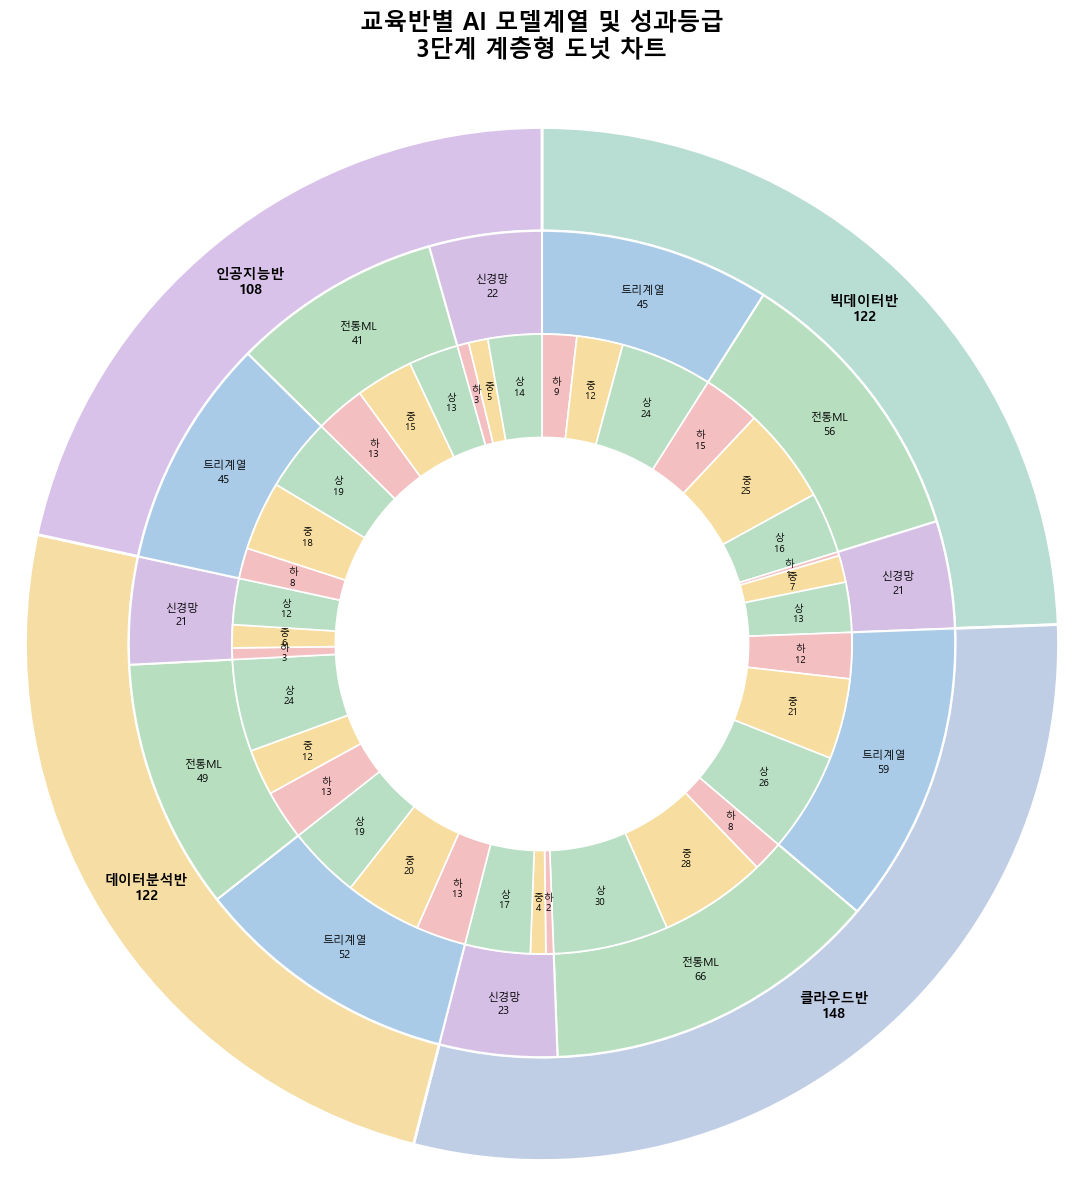

계층 구조: 교육반 → 모델계열 → 성과등급
vals 크기: (4, 3, 3)
전체 인원: 500

성과등급별 인원
score_grade
하    100
중    173
상    227
Name: count, dtype: int64

성과등급별 종합점수 요약


,count,min,mean,max
score_grade,,,,
하,100,65.2,81.3,84.9
중,173,85.1,87.7,90.0
상,227,90.0,92.8,97.4


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

donut_data = main_df.copy()

#  AI 모델을 3개 계열로 묶기
model_group_map = {
    'decision tree': '트리계열',
    'random forest': '트리계열',
    'knn': '전통ML',
    'svm': '전통ML',
    'neural network': '신경망'
}

# 대소문자를 통일한 뒤 모델계열로 변환
donut_data['model_group'] = (
    donut_data['model_type']
    .str.casefold()
    .map(model_group_map)
)


# 종합 점수 계산
score_columns = ['quiz_score', 'project_score', 'accuracy']

# 점수 컬럼 숫자형 변환
for column in score_columns:
    donut_data[column] = pd.to_numeric(
        donut_data[column],
        errors='coerce'
    )

# 퀴즈 점수, 프로젝트 점수, 정확도의 평균
donut_data['avg_score'] = (donut_data[score_columns].mean(axis=1))

# 실제 점수 기준으로 성과등급 생성
# 하: 85점 미만
# 중: 85점 이상 90점 미만
# 상: 90점 이상
donut_data['score_grade'] = pd.cut(
    donut_data['avg_score'],
    bins=[-np.inf, 85, 90, np.inf],
    labels=['하', '중', '상'],
    right=False
)

# 계층 라벨 설정 / 바깥: 교육반 → 가운데: 모델계열 → 안쪽: 성과등급
outer_labels = (donut_data['class_name'].unique().tolist())
model_group_labels = ['트리계열', '전통ML', '신경망']
score_grade_labels = ['하', '중', '상']

# 학생 수 집계
group_counts = (donut_data.groupby(
        ['class_name', 'model_group', 'score_grade'],
        observed=True
    ).size()
)

# 가능한 모든 조합 생성
full_index = pd.MultiIndex.from_product(
    [
        outer_labels,
        model_group_labels,
        score_grade_labels
    ],
    names=[
        'class_name',
        'model_group',
        'score_grade'
    ]
)

# 존재하지 않는 조합은 0으로 채우기
group_counts = group_counts.reindex(full_index, fill_value=0)

vals = group_counts.to_numpy().reshape(
    len(outer_labels),
    len(model_group_labels),
    len(score_grade_labels)
).astype(float)

# 고리 라벨
middle_labels = [model_group_labels.copy() for _ in outer_labels]
inner_labels = [[score_grade_labels.copy() for _ in model_group_labels] for _ in outer_labels]

total = vals.sum()
valsnorm = vals / total * 2 * np.pi

flat = valsnorm.flatten()
starts_flat = np.concatenate([[0], np.cumsum(flat[:-1])])
starts = starts_flat.reshape(vals.shape)

# 그래프 그리자
fig, ax = plt.subplots(figsize=(16, 12), subplot_kw=dict(projection='polar'))

ax.set_title(
    '교육반별 AI 모델계열 및 성과등급\n3단계 계층형 도넛 차트',
    fontsize=17,
    fontweight='bold',
    pad=20
)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ring = 0.2

# 바깥 고리: 교육반
outer_palette = [
    '#B8DDD3',  # 파스텔 민트
    '#BFCDE5',  # 파스텔 블루
    '#F6DDA4',  # 파스텔 옐로
    '#D9C2E9',  # 파스텔 퍼플
    '#F4C5C0',  # 파스텔 핑크
    '#C3E0E5'   # 파스텔 스카이
]

outer_colors = [outer_palette[i % len(outer_palette)] for i in range(len(outer_labels))]

# 가운데 고리: 모델계열
model_group_colors = [
    '#A9CBE8',  # 트리계열: 파스텔 블루
    '#B7DEBE',  # 전통ML: 파스텔 그린
    '#D6BFE5'   # 신경망: 파스텔 퍼플
]

# 교육반마다 세 가지 색상 반복
middle_colors = (model_group_colors * len(outer_labels))


# 안쪽 고리: 성과등급
grade_colors = [
    '#F4BFC1',  # 하: 파스텔 핑크
    '#F7DEA0',  # 중: 파스텔 옐로
    '#B8DFC4'   # 상: 파스텔 그린
]

# 교육반 수 × 모델계열 수만큼 반복
inner_colors = (
    grade_colors
    * (
        len(outer_labels)
        * len(model_group_labels)
    )
)


# =========================================================
# 바깥 고리: 교육반
# =========================================================

outer_widths = valsnorm.sum(axis=(1, 2))
outer_starts = starts[:, 0, 0]

ax.bar(
    x=outer_starts,
    width=outer_widths,
    bottom=1 - ring,
    height=ring,
    color=outer_colors,
    edgecolor='white',
    linewidth=2,
    align='edge'
)

# 교육반 이름과 학생 수 표시
for i in range(len(outer_labels)):

    group_sum = int(vals[i].sum())

    if group_sum == 0:
        continue

    theta_center = (outer_starts[i] + outer_widths[i] / 2)
    r_center = 1 - ring / 2

    ax.text(
        theta_center,
        r_center,
        f'{outer_labels[i]}\n{group_sum}',
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold'
    )


# =========================================================
# 가운데 고리: 모델계열
# =========================================================

# 성과등급 축을 합산
middle_widths = valsnorm.sum(axis=2)

# 각 모델계열의 첫 성과등급 시작 위치
middle_starts = starts[:, :, 0]

ax.bar(
    x=middle_starts.flatten(),
    width=middle_widths.flatten(),
    bottom=1 - 2 * ring,
    height=ring,
    color=middle_colors,
    edgecolor='white',
    linewidth=1.5,
    align='edge'
)

# 모델계열 이름과 학생 수 표시
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        middle_sum = int(vals[i, j].sum())

        if middle_sum == 0:
            continue

        theta_center = (middle_starts[i, j] + middle_widths[i, j] / 2)
        r_center = 1 - 1.5 * ring

        ax.text(
            theta_center,
            r_center,
            f'{middle_labels[i][j]}\n{middle_sum}',
            ha='center',
            va='center',
            fontsize=8
        )


# =========================================================
# 14. 안쪽 고리: 성과등급
# =========================================================

ax.bar(
    x=starts.flatten(),
    width=valsnorm.flatten(),
    bottom=1 - 3 * ring,
    height=ring,
    color=inner_colors,
    edgecolor='white',
    linewidth=1.2,
    align='edge'
)

# 상·중·하와 학생 수 표시
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        for k in range(vals.shape[2]):
            grade_count = int(vals[i, j, k])

            if grade_count == 0:
                continue

            theta_center = (starts[i, j, k] + valsnorm[i, j, k] / 2)
            r_center = 1 - 2.5 * ring

            ax.text(
                theta_center,
                r_center,
                f'{inner_labels[i][j][k]}\n{grade_count}',
                ha='center',
                va='center',
                fontsize=7
            )


# =========================================================
# 15. 그래프 마무리
# =========================================================

# 중앙에는 아무 글자도 표시하지 않음
ax.set_axis_off()
ax.set_ylim(0, 1.03)

plt.tight_layout()
plt.show()


# =========================================================
# 16. 결과 확인
# =========================================================

print('계층 구조: 교육반 → 모델계열 → 성과등급')
print('vals 크기:', vals.shape)
print('전체 인원:', int(vals.sum()))

print('\n성과등급별 인원')
print(
    donut_data['score_grade']
    .value_counts()
    .sort_index()
)

print('\n성과등급별 종합점수 요약')
display(
    donut_data
    .groupby('score_grade', observed=True)['avg_score']
    .agg(['count', 'min', 'mean', 'max'])
    .round(1)
)